Images loaded: 10

Image   Mean brightness   % pixels at 0 or 255   % outlier pixels
1       111.2             0.00                   0.00
2       101.7             0.00                   0.00
3       31.3              0.00                   0.00
4       0.2               99.63                  0.03
5       1.5               71.84                  0.00
6       60.2              0.00                   0.00
7       80.1              0.00                   0.00
8       39.7              0.00                   0.15
9       59.2              0.00                   0.00
10      83.0              0.00                   0.00


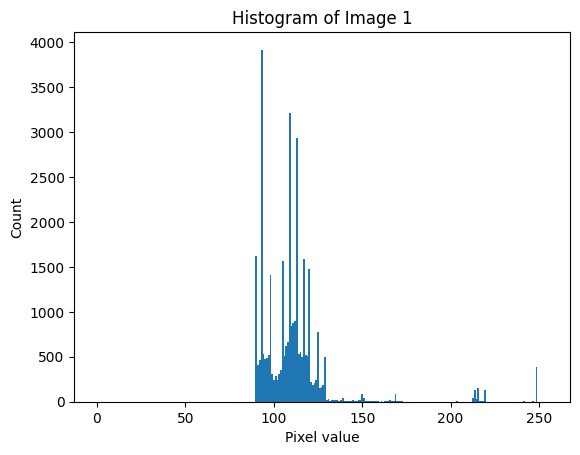


Average PSNR (dB)  - higher is better
Filter         Salt-Pepper 5%  Salt-Pepper 20%  Salt-Pepper 50%          Speckle
No filter               17.59            11.51             7.52            26.69
Median 3x3              37.50            28.56            14.37            30.26
Median 5x5              35.36            32.86            23.44            30.86
Median 7x7              34.15            31.95            27.75            30.49

Average edge score (max 1) - higher is better
Filter         Salt-Pepper 5%  Salt-Pepper 20%  Salt-Pepper 50%          Speckle
No filter                0.28             0.22             0.21             0.40
Median 3x3               0.84             0.70             0.28             0.51
Median 5x5               0.78             0.79             0.52             0.71
Median 7x7               0.72             0.73             0.66             0.63

Best median window for each noise type (highest PSNR):
Salt-Pepper 5% -> Median 3x3 (PSNR = 37.5 dB)
Sa

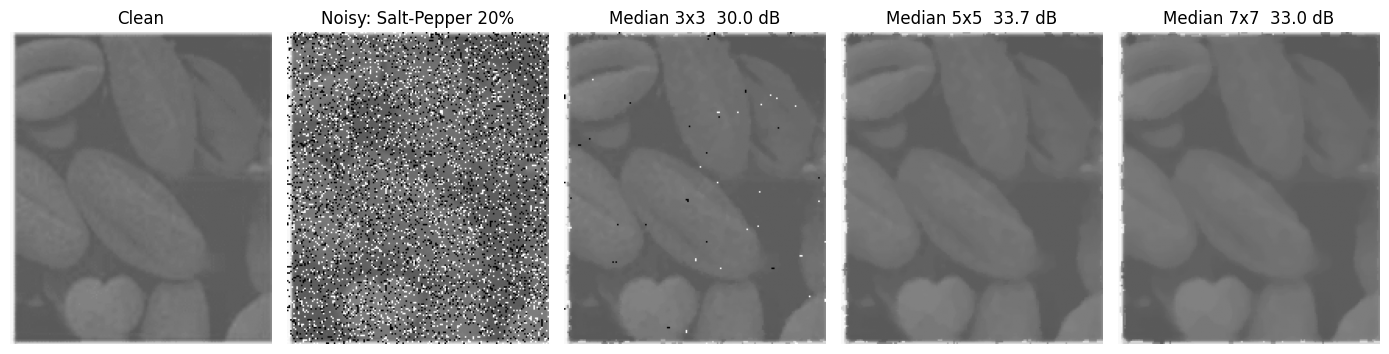

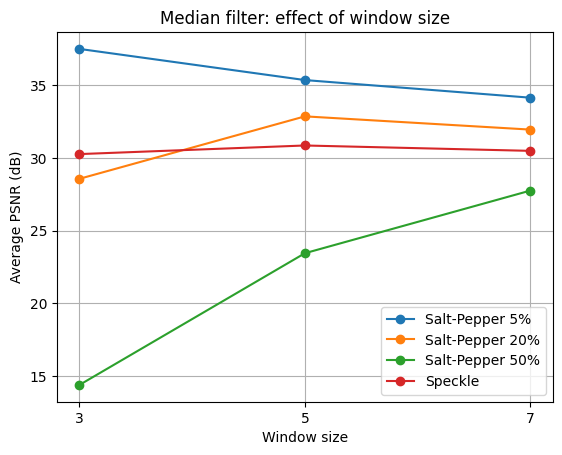

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)          # same random noise every time
SIZE = 200                  # longest side of each image (keeps the program fast)

def load_image(number):
    for ext in [".png", ".jpg", ".jpeg"]:
        img = cv2.imread("/content/image" + str(number) + ext, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            h, w = img.shape
            scale = SIZE / max(h, w)                        # keep the shape of the image
            return cv2.resize(img, (int(w * scale), int(h * scale)))
    return None

images = []
for n in range(1, 11):
    img = load_image(n)
    if img is not None:
        images.append(img)

print("Images loaded:", len(images))

print("\nImage   Mean brightness   % pixels at 0 or 255   % outlier pixels")
for i in range(len(images)):
    img = images[i]
    brightness = img.mean()
    extreme = (np.sum(img == 0) + np.sum(img == 255)) / img.size * 100
    med = cv2.medianBlur(img, 3)
    diff = np.abs(img.astype(int) - med.astype(int))
    outliers = np.mean(diff > 60) * 100
    print("%-7d %-17.1f %-22.2f %.2f" % (i + 1, brightness, extreme, outliers))

plt.hist(images[0].ravel(), bins=256, range=(0, 255))
plt.title("Histogram of Image 1")
plt.xlabel("Pixel value")
plt.ylabel("Count")
plt.show()

def add_salt_pepper(img, p):
    noisy = img.copy()
    r = np.random.rand(img.shape[0], img.shape[1])
    noisy[r < p / 2] = 0                       # pepper (black)
    noisy[(r >= p / 2) & (r < p)] = 255        # salt (white)
    return noisy

def add_speckle(img, std):
    f = img.astype(np.float64)
    n = np.random.normal(0, std, img.shape)
    noisy = f + f * n                          # g = f + f*n
    return np.clip(noisy, 0, 255).astype(np.uint8)

def make_noisy(noise_name, img):
    if noise_name == "Salt-Pepper 5%":
        return add_salt_pepper(img, 0.05)
    elif noise_name == "Salt-Pepper 20%":
        return add_salt_pepper(img, 0.20)
    elif noise_name == "Salt-Pepper 50%":
        return add_salt_pepper(img, 0.50)
    elif noise_name == "Speckle":
        return add_speckle(img, 0.3)

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    if mse == 0:
        return 99
    return 10 * np.log10(255 ** 2 / mse)

# Edge score: how many edges of the clean image are still found in the filtered image (1 = perfect)
kernel3 = np.ones((3, 3), np.uint8)

def edge_score(clean, out):
    scale = 255.0 / max(int(clean.max()), 1)                  # brighten both by the same factor
    c = np.clip(clean.astype(np.float64) * scale, 0, 255).astype(np.uint8)
    o = np.clip(out.astype(np.float64) * scale, 0, 255).astype(np.uint8)
    e1 = cv2.Canny(c, 100, 200) > 0
    e2 = cv2.Canny(o, 100, 200) > 0
    near1 = cv2.dilate(e1.astype(np.uint8), kernel3) > 0
    near2 = cv2.dilate(e2.astype(np.uint8), kernel3) > 0
    precision = (e2 & near1).sum() / max(e2.sum(), 1)
    recall = (e1 & near2).sum() / max(e1.sum(), 1)
    if precision + recall == 0:
        return 0
    return 2 * precision * recall / (precision + recall)

noise_list = ["Salt-Pepper 5%", "Salt-Pepper 20%", "Salt-Pepper 50%", "Speckle"]
window = {"Median 3x3": 3, "Median 5x5": 5, "Median 7x7": 7}
filter_list = ["No filter", "Median 3x3", "Median 5x5", "Median 7x7"]

psnr_avg = {}     # average PSNR for each (noise, filter)
edge_avg = {}     # average edge score for each (noise, filter)

for noise_name in noise_list:
    psnr_values = {}
    edge_values = {}
    for filter_name in filter_list:
        psnr_values[filter_name] = []
        edge_values[filter_name] = []

    for clean in images:
        noisy = make_noisy(noise_name, clean)        # noise made ONCE, same for every filter
        for filter_name in filter_list:
            if filter_name == "No filter":
                out = noisy
            else:
                out = cv2.medianBlur(noisy, window[filter_name])
            psnr_values[filter_name].append(psnr(clean, out))
            edge_values[filter_name].append(edge_score(clean, out))

    for filter_name in filter_list:
        psnr_avg[(noise_name, filter_name)] = np.mean(psnr_values[filter_name])
        edge_avg[(noise_name, filter_name)] = np.mean(edge_values[filter_name])

def print_table(title, table):
    print("\n" + title)
    print("%-12s" % "Filter", end="")
    for noise_name in noise_list:
        print("%17s" % noise_name, end="")
    print()
    for filter_name in filter_list:
        print("%-12s" % filter_name, end="")
        for noise_name in noise_list:
            print("%17.2f" % table[(noise_name, filter_name)], end="")
        print()

print_table("Average PSNR (dB)  - higher is better", psnr_avg)
print_table("Average edge score (max 1) - higher is better", edge_avg)

print("\nBest median window for each noise type (highest PSNR):")
for noise_name in noise_list:
    best_filter = filter_list[1]
    for filter_name in filter_list[1:]:
        if psnr_avg[(noise_name, filter_name)] > psnr_avg[(noise_name, best_filter)]:
            best_filter = filter_name
    print(noise_name, "->", best_filter, "(PSNR =", round(psnr_avg[(noise_name, best_filter)], 2), "dB)")

test_img = images[0]               # change the number to see another image
noise_to_show = "Salt-Pepper 20%"  # also try "Speckle" or "Salt-Pepper 50%"
noisy = make_noisy(noise_to_show, test_img)

plt.figure(figsize=(14, 3.5))
plt.subplot(1, 5, 1); plt.imshow(test_img, cmap="gray", vmin=0, vmax=255); plt.title("Clean"); plt.axis("off")
plt.subplot(1, 5, 2); plt.imshow(noisy, cmap="gray", vmin=0, vmax=255); plt.title("Noisy: " + noise_to_show); plt.axis("off")
for i in range(3):
    name = filter_list[i + 1]
    out = cv2.medianBlur(noisy, window[name])
    plt.subplot(1, 5, i + 3)
    plt.imshow(out, cmap="gray", vmin=0, vmax=255)
    plt.title(name + "  " + str(round(psnr(test_img, out), 1)) + " dB")
    plt.axis("off")
plt.tight_layout()
plt.show()

sizes = [3, 5, 7]
for noise_name in noise_list:
    values = []
    for k in sizes:
        values.append(psnr_avg[(noise_name, "Median " + str(k) + "x" + str(k))])
    plt.plot(sizes, values, marker="o", label=noise_name)

plt.xlabel("Window size")
plt.ylabel("Average PSNR (dB)")
plt.title("Median filter: effect of window size")
plt.xticks(sizes)
plt.grid(True)
plt.legend()
plt.show()